# Week 4 — Bayesian Inference for Observational Cosmology

## Expanded teaching edition

This version is designed so that a student can move from the lecture directly  
into Lab 04 without encountering undefined statistical or cosmological  
quantities.

The lecture will repeatedly distinguish four layers:

1. **observed data** — quantities contained in the catalogue;
2. **model prediction** — what the cosmological model predicts for those  
observations;
3. **parameters** — unknown quantities that control the model;
4. **probability model** — how observed data fluctuate around the prediction.

The central Pantheon+ teaching model is

$$
m_{B,i}^{\rm corr}
=
\mu(z_i;\Omega_m,H_0)
+
M_B
+
\epsilon_i.
$$

Every symbol in this equation will be defined before it is used in the lab.

## 0.1 What problem are we solving?

Pantheon+ provides standardized Type Ia supernova brightness information and  
redshifts.

We want to ask:

> Which combinations of the matter-density parameter $\Omega_m$ and the  
> supernova calibration parameter $M_B$ are compatible with the observed  
> Hubble diagram?

This is an **inverse problem**.

The forward direction is

$$
(\Omega_m,M_B)
\longrightarrow
m_B^{\rm model}(z)
\longrightarrow
\text{possible observations}.
$$

Bayesian inference reverses the scientific question:

$$
\text{observations}
\longrightarrow
p(\Omega_m,M_B\mid D).
$$

The posterior does not “invert” the forward model algebraically. It uses the  
likelihood and prior to quantify which parameter values remain plausible after  
the observations are known.

## 0.2 Data, parameters and fixed quantities

### Observed or released quantities

- $z_{\rm HD}$ — the Hubble-diagram redshift used by this teaching model.
- $m_B^{\rm corr}$ — the released standardized/corrected apparent magnitude.
- $C$ — the released covariance matrix used to describe uncertainty and  
correlations among the selected observations.

### Parameters inferred in Lab 04

- $\Omega_m$ — present-day matter-density parameter.
- $M_B$ — standardized supernova absolute-magnitude calibration parameter.

### Fixed teaching convention

- $H_0=70\ {\rm km\,s^{-1}\,Mpc^{-1}}$.

In Lab 04, $H_0$ is not inferred. It fixes the absolute distance scale so  
that the remaining zero-point freedom is absorbed into $M_B$.

## 0.3 What is $\Omega_m$?

The matter-density parameter is

$$
\Omega_m
=
\frac{
\rho_{m,0}
}{
\rho_{\rm crit,0}
},
$$

where

$$
\rho_{\rm crit,0}
=
\frac{
3H_0^2
}{
8\pi G
}.
$$

In the flat $\Lambda$CDM teaching model,

$$
\Omega_\Lambda
=
1-\Omega_m.
$$

Changing $\Omega_m$ changes the redshift dependence of the expansion rate,

$$
H(z)
=
H_0
\sqrt{
\Omega_m(1+z)^3
+
1-\Omega_m
},
$$

and therefore changes the **shape** of the predicted Hubble diagram.

## 0.4 What is $M_B$ and why is it a nuisance parameter?

$M_B$ is the standardized absolute-magnitude zero point of Type Ia  
supernovae.

It enters the predicted apparent magnitude through

$$
m_B^{\rm model}
=
\mu(z;\Omega_m,H_0)
+
M_B.
$$

A **nuisance parameter** is a parameter required by the statistical model but  
not necessarily the main scientific quantity we want to report.

Here the main cosmological interest is $\Omega_m$, but the model cannot predict  
apparent magnitudes without a luminosity zero point. Therefore $M_B$ must be  
included in the joint inference.

Bayesian inference handles this naturally: infer the joint posterior

$$
p(\Omega_m,M_B\mid D)
$$

and then marginalize over $M_B$ when reporting $\Omega_m$.

## 0.5 What is the distance modulus?

The luminosity distance $D_L$ is related to flux through

$$
F
=
\frac{
L
}{
4\pi D_L^2
}.
$$

The distance modulus is

$$
\mu
=
m-M
=
5\log_{10}
\left(
\frac{
D_L
}{
{\rm Mpc}
}
\right)
+
25.
$$

For a flat cosmology,

$$
D_L(z)
=
(1+z)
\frac{c}{H_0}
\int_0^z
\frac{
dz'
}{
E(z')
},
$$

with

$$
E(z)
=
\frac{H(z)}{H_0}.
$$

Thus

$$
\Omega_m
\rightarrow
H(z)
\rightarrow
D_L(z)
\rightarrow
\mu(z)
\rightarrow
m_B^{\rm model}(z).
$$

## 0.6 What is a residual?

For each observation,

$$
\Delta_i
=
m_{B,i}^{\rm corr}
-
m_{B,i}^{\rm model}.
$$

In vector form,

$$
\boldsymbol\Delta
=
\mathbf m_B^{\rm corr}
-
\mathbf m_B^{\rm model}.
$$

A residual is therefore the difference between what was observed and what the  
model predicts at a chosen parameter value.

Residuals are not themselves cosmological parameters. They are diagnostic  
quantities that connect the model to the likelihood.

## 0.7 What is a likelihood surface?

With two parameters, the likelihood is not a single number.

For every pair

$$
(\Omega_m,M_B)
$$

we calculate

$$
\mathcal L(\Omega_m,M_B).
$$

The result is a surface over a two-dimensional parameter plane.

High regions of this surface correspond to parameter combinations under which  
the observed data are relatively compatible with the adopted model.

The surface can be narrow, broad, tilted, curved, multimodal or truncated by  
the chosen parameter domain. These shapes are collectively called the  
**geometry of the likelihood or posterior**.

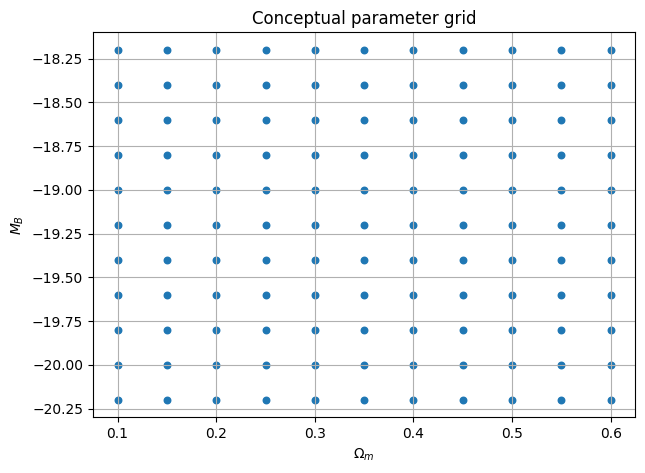

In [1]:
# Conceptual sketch: a two-dimensional parameter grid.

import numpy as np
import matplotlib.pyplot as plt

omega_demo = np.linspace(
    0.10,
    0.60,
    11,
)

mb_demo = np.linspace(
    -20.2,
    -18.2,
    11,
)

X, Y = np.meshgrid(
    omega_demo,
    mb_demo,
)

fig, ax = plt.subplots(
    figsize=(7, 5),
)

ax.scatter(
    X.ravel(),
    Y.ravel(),
    s=22,
)

ax.set_xlabel(
    r"$\Omega_m$"
)

ax.set_ylabel(
    r"$M_B$"
)

ax.set_title(
    "Conceptual parameter grid"
)

ax.grid(True)

plt.show()

### How to read the grid sketch

Each point represents one candidate model:

$$
(\Omega_{m,i},M_{B,j}).
$$

At that point we:

1. calculate the predicted Hubble relation;
2. calculate the residual vector;
3. evaluate $\chi^2$;
4. convert $\chi^2$ into a likelihood;
5. multiply by the prior;
6. normalize all grid cells to obtain the posterior.

With only two parameters, this direct calculation is transparent and avoids  
introducing MCMC before it is needed.

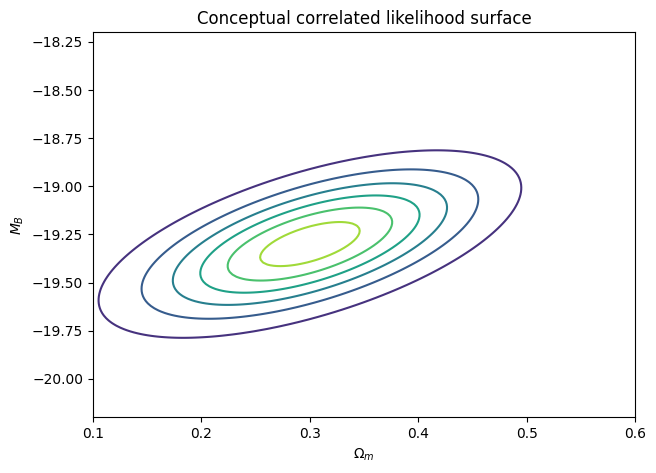

In [2]:
# Conceptual sketch: a correlated likelihood surface.

omega_demo = np.linspace(
    0.10,
    0.60,
    160,
)

mb_demo = np.linspace(
    -20.2,
    -18.2,
    160,
)

X, Y = np.meshgrid(
    omega_demo,
    mb_demo,
)

x0 = 0.30
y0 = -19.30

u = (
    (X - x0) / 0.08
)

v = (
    (Y - y0) / 0.20
)

Z = np.exp(
    -0.5
    * (
        u**2
        + v**2
        - 1.2 * u * v
    )
)

fig, ax = plt.subplots(
    figsize=(7, 5),
)

ax.contour(
    X,
    Y,
    Z,
    levels=7,
)

ax.set_xlabel(
    r"$\Omega_m$"
)

ax.set_ylabel(
    r"$M_B$"
)

ax.set_title(
    "Conceptual correlated likelihood surface"
)

plt.show()

### What does a tilted contour mean?

A tilted likelihood or posterior means that the parameters are not independent  
in the inference.

Moving $\Omega_m$ away from its preferred value may be partly compensated by  
moving $M_B$ in a correlated direction.

This is a **parameter degeneracy**.

A degeneracy does not mean that the model has failed. It means that the data  
constrain some combinations of parameters more strongly than others.

## 0.8 Core statistical vocabulary used later

### Parameter

An unknown quantity controlling the model, such as $\Omega_m$ or $M_B$.

### Nuisance parameter

A parameter required by the model but not the primary scientific target.

### Likelihood

The probability of the observed data evaluated as a function of the  
parameters:

$$
\mathcal L(\theta)
=
p(D\mid\theta).
$$

### Prior

A probability distribution over parameter values before conditioning on the  
current dataset:

$$
p(\theta).
$$

### Posterior

The probability distribution over parameter values after conditioning on the  
data:

$$
p(\theta\mid D).
$$

### Evidence

The normalizing probability of the data under the model:

$$
p(D)
=
\int
p(D\mid\theta)
p(\theta)
\,d\theta.
$$

### Profiling

**Profiling** removes a nuisance parameter by optimization.

For every fixed $\Omega_m$, choose the value of $M_B$ that maximizes the  
likelihood:

$$
\mathcal L_{\rm prof}(\Omega_m)
=
\max_{M_B}
\mathcal L(\Omega_m,M_B).
$$

Profiling therefore keeps only one nuisance value at each $\Omega_m$.

It is a frequentist likelihood operation and was used conceptually in Lab 03.

### Marginalization

**Marginalization** removes a nuisance parameter by integration:

$$
p(\Omega_m\mid D)
=
\int
p(\Omega_m,M_B\mid D)
\,dM_B.
$$

Marginalization keeps the contribution of **all** nuisance-parameter values,  
weighted by their posterior probability.

Therefore

$$
\boxed{
\text{profiling}
\neq
\text{marginalization}.
}
$$

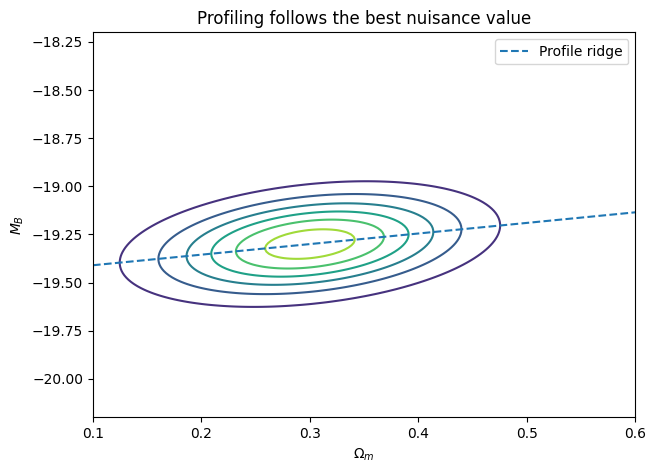

In [3]:
# Conceptual sketch:
# profile path through a joint surface.

omega_demo = np.linspace(
    0.10,
    0.60,
    180,
)

mb_demo = np.linspace(
    -20.2,
    -18.2,
    180,
)

X, Y = np.meshgrid(
    omega_demo,
    mb_demo,
)

ridge = (
    -19.30
    + 0.55
    * (X - 0.30)
)

Z = np.exp(
    -0.5
    * (
        ((X - 0.30) / 0.09) ** 2
        + ((Y - ridge) / 0.16) ** 2
    )
)

profile_y = (
    -19.30
    + 0.55
    * (omega_demo - 0.30)
)

fig, ax = plt.subplots(
    figsize=(7, 5),
)

ax.contour(
    X,
    Y,
    Z,
    levels=7,
)

ax.plot(
    omega_demo,
    profile_y,
    linestyle="--",
    label="Profile ridge",
)

ax.set_xlabel(
    r"$\Omega_m$"
)

ax.set_ylabel(
    r"$M_B$"
)

ax.set_title(
    "Profiling follows the best nuisance value"
)

ax.legend()

plt.show()

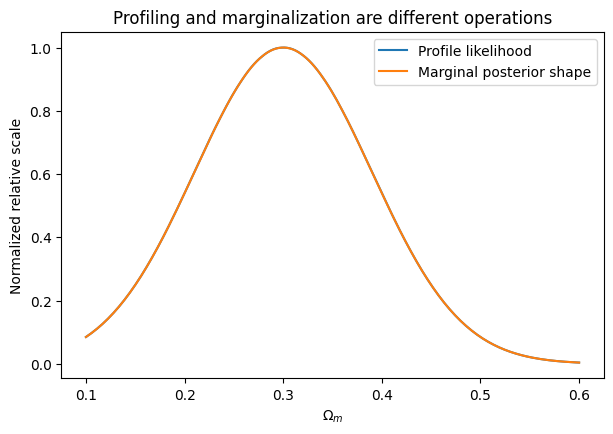

In [4]:
# Conceptual comparison:
# profile likelihood versus marginal posterior.

omega_demo = np.linspace(
    0.10,
    0.60,
    180,
)

mb_demo = np.linspace(
    -20.2,
    -18.2,
    180,
)

X, Y = np.meshgrid(
    omega_demo,
    mb_demo,
)

ridge = (
    -19.30
    + 0.55
    * (X - 0.30)
)

joint_demo = np.exp(
    -0.5
    * (
        ((X - 0.30) / 0.09) ** 2
        + ((Y - ridge) / 0.16) ** 2
    )
)

profile_demo = joint_demo.max(
    axis=0
)

marginal_demo = joint_demo.sum(
    axis=0
)

profile_demo /= profile_demo.max()
marginal_demo /= marginal_demo.max()

fig, ax = plt.subplots(
    figsize=(7, 4.5),
)

ax.plot(
    omega_demo,
    profile_demo,
    label="Profile likelihood",
)

ax.plot(
    omega_demo,
    marginal_demo,
    label="Marginal posterior shape",
)

ax.set_xlabel(
    r"$\Omega_m$"
)

ax.set_ylabel(
    "Normalized relative scale"
)

ax.set_title(
    "Profiling and marginalization are different operations"
)

ax.legend()

plt.show()

### Why the two one-dimensional curves can differ

Profiling asks only for the best $M_B$ available at each $\Omega_m$.

Marginalization also cares about the **volume** of plausible nuisance values  
around that point.

A parameter value can therefore have a high profile likelihood but relatively  
little marginalized posterior mass if only a very narrow range of $M_B$ is  
compatible with it.

This distinction is one of the most important conceptual bridges from Lab 03  
to Lab 04.

## 0.9 Symbols that appear in Lab 04

- $D$ — the selected Pantheon+ dataset used in the likelihood.
- $N$ — number of selected observations.
- $z_i$ — redshift of observation $i$.
- $m_{B,i}^{\rm corr}$ — observed standardized magnitude.
- $\Omega_m$ — matter-density parameter.
- $M_B$ — nuisance absolute-magnitude zero point.
- $H_0$ — fixed teaching zero-point convention.
- $\mu(z)$ — distance modulus predicted by the cosmology.
- $\mathbf1$ — vector of ones with length $N$.
- $\Delta$ — residual vector.
- $C$ — covariance matrix.
- $C^{-1}$ — inverse covariance as a mathematical object; the code uses a  
Cholesky solve rather than constructing it explicitly.
- $\chi^2$ — covariance-weighted residual quadratic form.
- $\mathcal L$ — likelihood.
- $p(\theta)$ — prior.
- $p(\theta\mid D)$ — posterior.
- $a(\Omega_m)$, $b(\Omega_m)$, $d$ — coefficients used to evaluate the  
quadratic dependence on $M_B$ efficiently.
- `OMEGA_GRID` — evaluated values of $\Omega_m$.
- `MB_GRID` — evaluated values of $M_B$.
- `CHI2` — two-dimensional array of $\chi^2$ values.
- `logL` — log-likelihood values.
- `P` — normalized posterior probability mass on the regular grid.
- `p_om` — marginalized posterior for $\Omega_m$.
- `p_mb` — marginalized posterior for $M_B$.

## Lecture map

| Time | Topic |
|---|---|
| 0:00–0:15 | Notation and why notation matters |
| 0:15–0:35 | Bayes' theorem and the full inference problem |
| 0:35–1:05 | Likelihood construction and astronomical measurement error |
| 1:05–1:35 | Priors, prior failure modes and prior predictive reasoning |
| 1:35–1:45 | Break |
| 1:45–2:10 | Joint Pantheon+ posterior and computation on a grid |
| 2:10–2:30 | Marginalization, posterior summaries and credible regions |
| 2:30–2:45 | Prior sensitivity and external information |
| 2:45–2:58 | Posterior prediction and posterior predictive checks |
| 2:58–3:00 | Workflow checklist and bridge to Lab 04 / Week 5 |

### External learning material

- Casey: *Practical Bayesian Inference in Astronomy*
- Eadie et al. (2023): practical Bayesian guidance for astronomy
- Crete 06 Bayesian notebooks

# 1. Notation: why it matters

Bayesian papers across astronomy, physics and statistics often use different  
symbols for the same objects. The important point is not merely consistency of  
notation: notation tells us **what is a function of what**.

For example,

$$
p(y\mid\theta)
$$

emphasizes a probability distribution over possible data $y$ for a fixed  
parameter value $\theta$.

The same mathematical quantity can be written as

$$
\mathcal L(\theta;y),
$$

which emphasizes that the observed dataset $y$ is fixed while the function  
is examined over parameter space.

The numerical value is the same. The interpretation is different.

## 1.1 Notation used in this course

| Symbol | Meaning |
|---|---|
| $\theta$ | unknown model parameters |
| $y$ or $D$ | observed data |
| $\tilde y$ | replicated or future data |
| $p(\theta)$ | prior |
| $p(y\mid\theta)$ | probability model for data / likelihood |
| $p(\theta\mid y)$ | posterior |
| $p(\tilde y\mid y)$ | posterior predictive distribution |

For Lab 04,

$$
\theta=(\Omega_m,M_B),
$$

and the observations are the released Pantheon+ standardized apparent  
magnitudes, redshifts and covariance information.

## 1.2 Probability model versus likelihood

The expression $p(y\mid\theta)$ appears throughout Bayesian inference, but its  
interpretation depends on which quantity we imagine varying. This distinction  
is easy to overlook because the numerical expression is the same in both  
cases.

For fixed parameter values $\theta$, the function

$$
p(y\mid\theta)
$$

describes the probability distribution of all datasets that could have been  
generated under those parameter values. It must therefore be normalized over  
the space of possible observations:

$$
\int p(y\mid\theta)\,dy = 1.
$$

This is the **sampling-model interpretation**.

Once the experiment has been performed, however, the observed dataset $y_{\rm obs}$  
is fixed. We then evaluate exactly the same mathematical function at the  
observed data and regard it as a function of the parameters:

$$
\mathcal L(\theta;y_{\rm obs})
=
p(y_{\rm obs}\mid\theta).
$$

This is the **likelihood interpretation**. The likelihood tells us how  
compatible different parameter values are with the observations under the  
assumed data-generating model. It is not, by itself, a probability  
distribution over the parameters and therefore is not required to satisfy

$$
\int \mathcal L(\theta;y_{\rm obs})\,d\theta = 1.
$$

In general, that integral will not equal one.

> **Key point**
>
> The likelihood answers: “If these parameter values were true, how  
> compatible would the observed dataset be with the model?”  
> The posterior answers a different question: “After combining the  
> likelihood with prior information, how is probability distributed over  
> the parameter values?”

This distinction is the conceptual bridge between the maximum-likelihood  
analysis in Week 3 and Bayesian inference in Week 4.

### Instructor prompt

Ask:

> If the likelihood is larger at $\Omega_m=0.30$ than at $\Omega_m=0.40$, can  
> we immediately say that $\Omega_m=0.30$ is more probable?

**Answer:** not yet. We need the prior and posterior normalization.

This is the conceptual bridge from **Lab 03 maximum likelihood** to **Week 4  
Bayesian inference**.

# 2. The Bayesian inference problem

A complete Bayesian analysis needs:

1. a **likelihood** $p(y\mid\theta)$;
2. a **prior** $p(\theta)$;
3. a procedure for obtaining or approximating the **posterior** $p(\theta\mid y)$.

The likelihood describes how parameters generate observations.

The prior describes which parameter values were plausible before conditioning  
on the current dataset.

The posterior combines the two after we observe the data.

## 2.1 The joint distribution and derivation of Bayes' theorem

Before observing the current dataset, a Bayesian model describes the joint  
behavior of the unknown parameters and the data that those parameters could  
generate. That complete probabilistic statement is

$$
p(y,\theta)
=
p(y\mid\theta)\,p(\theta).
$$

The factor $p(\theta)$ describes which parameter values were considered plausible  
before looking at the current observations. The factor $p(y\mid\theta)$ describes how  
those parameter values would generate observable data.

The same joint distribution can be factorized in the opposite order:

$$
p(y,\theta)
=
p(\theta\mid y)\,p(y).
$$

The quantity $p(\theta\mid y)$ is the posterior distribution that we want. The quantity  
$p(y)$ is the marginal probability of the observed data under the full model.

Because both equations describe the same joint distribution, we can equate  
them:

$$
p(y\mid\theta)p(\theta)
=
p(\theta\mid y)p(y).
$$

Solving for the posterior gives Bayes' theorem:

$$
\boxed{
p(\theta\mid y)
=
\frac{
p(y\mid\theta)p(\theta)
}{
p(y)
}
}.
$$

Bayes' theorem should therefore not be viewed as an isolated formula to  
memorize. It is simply the consequence of writing the same joint probability  
distribution in two different factorizations.

## 2.2 Why the evidence appears

A posterior distribution must be normalized over parameter space:

$$
\int p(\theta\mid y)\,d\theta = 1.
$$

If we substitute Bayes' theorem,

$$
1
=
\frac{1}{p(y)}
\int
p(y\mid\theta)p(\theta)\,d\theta.
$$

Therefore,

$$
\boxed{
p(y)
=
\int
p(y\mid\theta)p(\theta)\,d\theta
}.
$$

The evidence is thus the normalization constant required to convert the  
unnormalized product

$$
p(y\mid\theta)p(\theta)
$$

into a proper probability distribution over $\theta$.

The evidence is also called the **marginal likelihood** because the parameter  
has been integrated out. For ordinary parameter estimation we often do not  
need its numerical value explicitly, because it is constant with respect to  
$\theta$. We can then write

$$
p(\theta\mid y)
\propto
p(y\mid\theta)p(\theta).
$$

For model-comparison problems, however, the evidence can become scientifically  
important because different models may assign very different integrated  
probabilities to the same dataset.

## 2.3 Cosmology translation

For the Pantheon+ teaching problem,

$$
\theta=(\Omega_m,M_B).
$$

Thus

$$
p(\Omega_m,M_B\mid D)
\propto
p(D\mid\Omega_m,M_B)
p(\Omega_m,M_B).
$$

If the prior is factorized,

$$
p(\Omega_m,M_B)
=
p(\Omega_m)p(M_B),
$$

then

$$
p(\Omega_m,M_B\mid D)
\propto
p(D\mid\Omega_m,M_B)
p(\Omega_m)p(M_B).
$$

That factorization is itself a modelling assumption.

# 3. The likelihood: your model of the data-generating process

The likelihood is where the scientific model meets the observational process.

A scientifically appropriate likelihood should reflect:

- what type of random variable was measured;
- the support of the data;
- the expected value under the model;
- measurement uncertainty;
- intrinsic physical scatter if present;
- covariance/dependence among observations.

A poor likelihood can produce a mathematically precise posterior that answers  
the wrong scientific question.

## 3.1 Choosing a likelihood family

Choosing the likelihood is one of the most important modelling decisions in  
the entire Bayesian workflow. The likelihood should describe the statistical  
properties of the **actual observed data product**, not merely the physical  
quantity that we ultimately care about.

For photon or event counts, a Poisson likelihood is often appropriate because  
the observations are non-negative integers generated by a counting process.  
For detection or non-detection outcomes, a Bernoulli or Binomial model can be  
natural. For real-valued measurements with approximately additive symmetric  
noise, a Normal likelihood is often a useful approximation. For quantities  
that are genuinely restricted to positive values, a Gamma or LogNormal model  
may be more appropriate.

The choice must always be tied to the measurement process. A true physical  
flux, for example, is positive. A background-subtracted estimator of that flux  
can nevertheless be negative because the estimator contains noise. In that  
case a Gaussian model for the measured estimator may be reasonable even though  
the latent physical flux itself cannot be negative.

> **Practical rule**
>
> Ask first: “What exactly is stored in the table?”  
> Then ask: “What probability model describes repeated measurements of that  
> data product under fixed physical parameters?”

This is why careful inspection of observational data products is a statistical  
task, not merely bookkeeping.

## 3.2 Measurement-error structures

Measurement uncertainty can enter a likelihood in several qualitatively  
different ways. It is important to distinguish them because each case implies  
a different statistical model and different assumptions about how much  
information each observation contains.

### Homoscedastic known errors

The simplest case assumes that every observation has the same known  
measurement uncertainty:

$$
y_i
\sim
\mathcal N
\left(
f_i(\theta),
\sigma^2
\right).
$$

Here the model prediction for observation $i$ is $f_i(\theta)$, and every  
measurement is assumed to have the same noise scale $\sigma$. This can be a  
reasonable approximation in a controlled experiment where all observations  
have similar exposure time, signal-to-noise ratio, calibration quality and  
instrumental conditions.

In astronomy, however, strictly homoscedastic data are comparatively rare.  
Different objects often have different brightnesses, observing conditions,  
cadences, exposure times and instrumental backgrounds.

### Heteroscedastic known errors

A more realistic astronomical situation is

$$
y_i
\sim
\mathcal N
\left(
f_i(\theta),
\sigma_i^2
\right).
$$

Now each observation has its own quoted uncertainty $\sigma_i$. A measurement with  
small $\sigma_i$ is more informative than one with large $\sigma_i$, and the  
likelihood automatically gives the high-precision observation greater  
statistical weight.

This structure appears throughout observational astronomy. Supernovae, AGN  
light-curve points, photometric measurements and radial velocities rarely all  
have identical uncertainty.

### Unknown noise scale

Sometimes the nominal noise level is not known well enough to be treated as a  
fixed number. We then promote the noise scale to an inferred parameter:

$$
y_i
\sim
\mathcal N
\left(
f_i(\theta),
\sigma^2
\right),
\qquad
\sigma
\sim
p(\sigma).
$$

The uncertainty scale is now part of the scientific model. The posterior must  
learn both the parameters controlling the mean relation and the parameter  
controlling the width of the distribution.

This changes the likelihood because the Gaussian normalization depends on  
$\sigma$. We are no longer allowed to discard that normalization as a constant.

### Intrinsic scatter

A further possibility is that the quoted measurement errors are correct, but  
the physical population itself has additional scatter around the deterministic  
relation. Then a simple model is

$$
y_i
\sim
\mathcal N
\left[
f_i(\theta),
\sigma_i^2
+
\sigma_{\rm int}^2
\right].
$$

The quantity $\sigma_{\rm int}$ represents astrophysical dispersion that is not explained  
by the measurement uncertainty alone.

If true intrinsic scatter exists but is omitted, the model attributes too much  
information to each measurement. The posterior then becomes artificially  
narrow and overconfident. Conversely, adding an unnecessary scatter parameter  
can make a model too flexible, so intrinsic scatter should be scientifically  
motivated and checked against the data.

> **Interpretation**
>
> Measurement error describes uncertainty in the observation. Intrinsic  
> scatter describes real dispersion in the underlying population. The two  
> enter the likelihood differently even though both broaden the observed  
> distribution.

## 3.3 Why Gaussian normalization matters

The complete Gaussian density is

$$
p(y_i\mid\mu_i,\sigma_i)
=
\frac{1}{
\sqrt{2\pi\sigma_i^2}
}
\exp
\left[
-\frac{
(y_i-\mu_i)^2
}{
2\sigma_i^2
}
\right].
$$

When $\sigma_i$ is known and fixed, the normalization factor can be constant with  
respect to the parameters controlling the mean model. In that special case, it  
may be dropped when we only need relative likelihood values or the location of  
the maximum.

The situation changes when the variance itself contains an inferred parameter.  
For example, if

$$
\sigma_{\rm tot,i}^2
=
\sigma_i^2
+
\sigma_{\rm int}^2,
$$

then both the exponential term and the normalization depend on $\sigma_{\rm int}$.

If we kept only the residual term and discarded the normalization, the model  
could increase the scatter indefinitely and make every residual look  
acceptable. The normalization penalizes excessively broad distributions and is  
essential for identifying a meaningful scatter scale.

> **Rule**
>
> A term may be removed from the likelihood only if it is truly constant with  
> respect to every parameter being inferred.

## 3.4 Independent-data log-likelihood

If the observations are conditionally independent given the parameters, the  
joint likelihood factorizes:

$$
p(y\mid\theta)
=
\prod_{i=1}^{N}
p(y_i\mid\theta).
$$

Taking logarithms converts the product into a sum:

$$
\log p(y\mid\theta)
=
\sum_{i=1}^{N}
\log p(y_i\mid\theta).
$$

This is useful both mathematically and numerically. Multiplying many very  
small probabilities can underflow in floating-point arithmetic, whereas  
summing log-probabilities is stable.

For heteroscedastic Gaussian measurements,

$$
\log p(y\mid\theta)
=
-\frac12
\sum_i
\left[
\frac{
(y_i-f_i(\theta))^2
}{
\sigma_i^2
}
+
\log
\left(
2\pi\sigma_i^2
\right)
\right].
$$

The first term measures how far each observation lies from the model  
prediction in units of its uncertainty. The second term accounts for the width  
of the corresponding probability distribution.

## 3.5 From Gaussian likelihood to $\chi^2$

If the observational uncertainties are fixed and independent of the  
parameters, the Gaussian log-likelihood can be written as a constant minus one  
half of the usual chi-square statistic:

$$
\chi^2(\theta)
=
\sum_i
\frac{
[y_i-f_i(\theta)]^2
}{
\sigma_i^2
}.
$$

Therefore,

$$
\log\mathcal L(\theta)
=
-\frac12
\chi^2(\theta)
+
\text{constant}.
$$

Exponentiating gives

$$
\mathcal L(\theta)
\propto
\exp
\left[
-\frac12
\chi^2(\theta)
\right].
$$

This explains why least-squares fitting and maximum-likelihood fitting are  
closely related when Gaussian errors are assumed.

It also gives the clean pedagogical bridge from Lab 03 to Week 4:

$$
\boxed{
\chi^2
\rightarrow
\mathcal L
\rightarrow
\mathcal L\,p(\theta)
\rightarrow
p(\theta\mid y)
}.
$$

The Bayesian analysis does not discard the likelihood used in Week 3. It  
embeds that likelihood inside a larger probability model that also includes  
prior information and posterior normalization.

## 3.6 Pantheon+ covariance likelihood

For the Pantheon+ teaching model we write

$$
m_{B,i}^{\rm corr}
=
\mu(z_i;\Omega_m,H_0)
+
M_B
+
\epsilon_i.
$$

The residual vector is

$$
\Delta(\Omega_m,M_B)
=
\mathbf m_B^{\rm corr}
-
\left[
\boldsymbol\mu(\mathbf z;\Omega_m,H_0)
+
M_B\mathbf1
\right].
$$

If the residual vector is modelled as a multivariate Gaussian,

$$
\Delta
\sim
\mathcal N(\mathbf0,C),
$$

then the likelihood is

$$
p(D\mid\Omega_m,M_B)
=
\frac{
\exp
\left[
-\frac12
\Delta^T C^{-1}\Delta
\right]
}{
(2\pi)^{N/2}
|C|^{1/2}
}.
$$

The covariance matrix $C$ contains not only the variance of each  
measurement on the diagonal, but also any covariance between measurements  
represented in the released statistical model.

Taking logarithms gives

$$
\log\mathcal L
=
-\frac12
\left[
\Delta^T C^{-1}\Delta
+
\log|C|
+
N\log(2\pi)
\right].
$$

If $C$ is fixed with respect to $\Omega_m$ and $M_B$, the last two terms are  
constant over the parameter grid. Relative posterior probabilities can then be  
computed from the quadratic form alone.

Taking logs,

$$
\log\mathcal L
=
-\frac12
\left[
\Delta^TC^{-1}\Delta
+
\log|C|
+
N\log(2\pi)
\right].
$$

If the covariance $C$ is fixed,

$$
\log|C|+N\log(2\pi)
$$

is constant in $(\Omega_m,M_B)$.

Therefore,

$$
\boxed{
\log\mathcal L
\propto
-\frac12\chi^2
}
$$

with

$$
\boxed{
\chi^2
=
\Delta^TC^{-1}\Delta.
}
$$

This is the likelihood used in Lab 04.

## 3.7 Why covariance matters

If the covariance matrix is diagonal,

$$
C
=
\operatorname{diag}
(\sigma_1^2,\ldots,\sigma_N^2),
$$

then the quadratic form becomes

$$
\Delta^T C^{-1}\Delta
=
\sum_i
\frac{
\Delta_i^2
}{
\sigma_i^2
}.
$$

This is the familiar expression for independent Gaussian measurements.

If off-diagonal elements are non-zero, however, the data contain correlated  
uncertainty. Two observations may share calibration information or other  
systematic contributions, and therefore cannot be treated as statistically  
independent pieces of information.

Ignoring those correlations usually changes the width and orientation of the  
likelihood in parameter space. In a cosmological analysis this can lead to  
posterior intervals that are too narrow or to an incorrect degeneracy  
structure.

Lab 04 uses the released statistical covariance. Week 5 deliberately extends  
the model to the statistical-plus-systematic covariance so that students can  
see how the posterior changes when more realistic correlated uncertainty is  
included.

# 4. The prior distribution

The prior

$$
p(\theta)
$$

encodes information about parameter values before conditioning on the present  
data.

In astronomy that information can come from:

- physical boundaries;
- known scales;
- calibration knowledge;
- previous independent experiments;
- dimensional/positivity constraints.

A prior makes these assumptions explicit.

## 4.1 Prior taxonomy

A **proper prior** is a probability distribution that can be normalized:

$$
\int
p(\theta)\,d\theta
=
1.
$$

An **improper prior** does not have a finite normalization. Improper priors  
can sometimes be used safely when the resulting posterior is proper, but that  
must be demonstrated rather than assumed. In this course we prefer proper  
priors unless there is a compelling reason to do otherwise.

An **informative prior** concentrates substantial probability in a relatively  
small region because independent information already constrains the parameter.  
A **weakly informative prior** is broader: it rules out absurd or physically  
implausible values while still allowing the current data to move the posterior  
substantially.

A prior that is visually flat is sometimes called “non-informative,” but that  
description is dangerous. Flatness depends on parameterization, and even a  
bounded uniform prior contains information through its support and boundaries.

A **conjugate prior** is chosen so that the posterior belongs to the same  
mathematical family as the prior. Conjugacy is useful for building intuition,  
but most realistic astronomical likelihoods and models are not simple enough  
for conjugate analysis.

## 4.2 Why “flat” is parameterization-dependent

Suppose the model is written in terms of a parameter $\theta$, and we define a  
transformed parameter

$$
\phi
=
g(\theta).
$$

Probability must be preserved under the change of variables:

$$
p_\phi(\phi)\,d\phi
=
p_\theta(\theta)\,d\theta.
$$

Therefore,

$$
\boxed{
p_\phi(\phi)
=
p_\theta(\theta)
\left|
\frac{d\theta}{d\phi}
\right|
}.
$$

This Jacobian factor means that a density that is uniform in $\theta$ will  
usually not be uniform in $\phi$.

The issue is important whenever astronomy uses nonlinear parameterizations:  
distance versus parallax, a scale $\sigma$ versus $\log\sigma$, mass versus log-mass,  
or a rate versus log-rate.

> **Interpretation**
>
> “Uniform prior” is incomplete language unless we also say *uniform in which  
> parameterization and over what support*.

## 4.3 Two prior failure modes

### Prior too broad

A prior can be so broad that it assigns substantial probability to values  
already known to be physically absurd. This may appear conservative, but it  
can produce unrealistic prior predictive observations, weak identifiability,  
poor numerical geometry and wasted computation.

A useful weakly informative prior should be broad relative to the expected  
posterior while still excluding clearly impossible or irrelevant regions.

### Prior too restrictive

The opposite problem occurs when the prior is so concentrated that plausible  
data cannot move the posterior very far. The result may then appear extremely  
precise even though much of that precision comes from the prior rather than  
the new observations.

The correct goal is not “make the prior as broad as possible.” The goal is to  
encode defensible knowledge transparently and then examine whether the final  
inference is sensitive to reasonable alternative prior choices.

## 4.4 Prior elicitation by parameter type

These are starting principles, not automatic recipes.

- **Location/intercept:** often a Normal prior centered on a physically motivated value.
- **Positive scale/scatter:** HalfNormal, Exponential, or a prior on $\log\sigma$.
- **Slope:** often Normal if both signs are plausible.
- **Probability $0<\eta<1$:** Beta.
- **Positive rate:** Gamma-family distributions can be natural.
- **Hard physical limit:** encode it explicitly in the support.

The correct check is not only “does the parameter range look reasonable?”

It is:

> What observations would this prior generate when combined with the  
> likelihood?

## 4.5 Prior predictive checking

A prior should be judged not only in parameter space but also through the  
observations it implies when combined with the likelihood.

Before seeing the current data, the model predicts

$$
p(y)
=
\int
p(y\mid\theta)
p(\theta)
\,d\theta.
$$

This is the **prior predictive distribution**.

A prior predictive check proceeds by drawing a parameter value from the prior,  
generating synthetic data from the likelihood, and inspecting whether those  
synthetic observations are scientifically plausible.

This can reveal problems that are difficult to see from the prior density  
alone. A broad prior on a cosmological or calibration parameter may look  
innocent numerically but generate absurd magnitudes, distances or residuals  
when propagated into observable space.

Prior predictive checking is therefore a model-development tool. It tests the  
combined implications of the prior and likelihood *before* the current data  
have been allowed to influence the posterior.

## 4.6 Lab 04 priors

Baseline:

$$
\Omega_m\sim U(0.10,0.60),
$$

$$
M_B\sim U(-20.2,-18.2).
$$

Inside the grid,

$$
p(\Omega_m,M_B)=\text{constant}.
$$

Therefore the posterior shape is proportional to the likelihood inside the  
allowed region.

But the prior still matters because it sets the support and boundaries.

## 4.7 Using previous measurements as priors

Previous measurements can provide scientifically meaningful priors, but only  
when the information being imported is genuinely independent of the current  
dataset.

Suppose an earlier experiment yields

$$
\theta
\sim
\mathcal N
(\mu_0,\sigma_0^2).
$$

If that experiment is independent and based on a compatible physical model,  
its posterior can be used as prior information for a new analysis.

The important danger is **double counting**. If the same observations were  
used to construct the prior and then appear again in the new likelihood, the  
information has been used twice. The posterior will be artificially narrow and  
will no longer represent a coherent update from independent evidence.

In cosmology this issue is particularly important because different published  
constraints may share surveys, calibration steps or external datasets.  
“Previous result” does not automatically mean “independent prior.”

## 4.8 Sequential Bayesian updating

Bayesian inference naturally supports sequential learning.

After observing a first independent dataset $y_1$,

$$
p(\theta\mid y_1)
\propto
p(y_1\mid\theta)p(\theta).
$$

If a second independent dataset $y_2$ is then collected, the posterior from  
the first analysis can become the prior for the second:

$$
p(\theta\mid y_1,y_2)
\propto
p(y_2\mid\theta)
p(\theta\mid y_1).
$$

Substituting the first posterior gives

$$
p(\theta\mid y_1,y_2)
\propto
p(y_2\mid\theta)
p(y_1\mid\theta)
p(\theta).
$$

Thus, when the datasets are conditionally independent given the parameters,  
sequential updating is mathematically equivalent to analysing the two datasets  
jointly.

The usefulness of this result is conceptual as well as computational: Bayesian  
inference formalizes the accumulation of independent scientific evidence.

# 5. Worked example: stellar distance from parallax

A star at distance $d$ kpc has parallax

$$
\varpi=\frac1d
$$

in milliarcseconds.

We observe a noisy parallax $y$ with quoted uncertainty $\sigma$.

The parameter of interest is $d$; the measured quantity is $y$.

## 5.1 Likelihood in parallax and distance space

Assume

$$
y\mid\varpi,\sigma
\sim
\mathcal N(\varpi,\sigma^2).
$$

Since

$$
\varpi=\frac1d,
$$

$$
p(y\mid d,\sigma)
=
\frac1{\sqrt{2\pi\sigma^2}}
\exp\left[
-\frac{(y-1/d)^2}{2\sigma^2}
\right].
$$

This is Gaussian as a probability distribution over possible measurements  
$y$ for fixed $d$.

As a function of distance for fixed measured $y$, it is generally  
asymmetric because of the nonlinear $1/d$ transformation.

## 5.2 Three candidate distance priors

### Uniform in parallax

$$
p(\varpi)\propto1.
$$

Since $\varpi=1/d$,

$$
p(d)
\propto
\left|\frac{d\varpi}{dd}\right|
=
\frac1{d^2}.
$$

### Uniform in distance

$$
p(d)\propto1
$$

over finite support.

### Exponentially decreasing space-density prior

$$
p(d)\propto d^2e^{-d/L}.
$$

The $d^2$ term reflects spherical-shell volume. The exponential term  
represents decreasing stellar density at large distances. The scale $L$  
encodes domain knowledge.

/tmp/ipykernel_1764/1989470660.py:19: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(p, x)


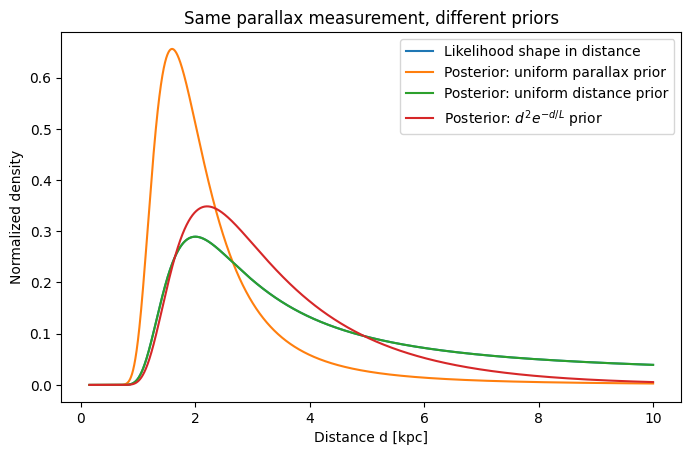

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Pedagogical example only.
y = 0.50      # measured parallax [mas]
sigma = 0.20  # quoted uncertainty [mas]
d = np.linspace(0.15, 10.0, 5000)  # kpc

log_like = -0.5*((y - 1.0/d)/sigma)**2
like = np.exp(log_like - np.max(log_like))

prior_uniform_parallax = 1.0/d**2
prior_uniform_distance = np.ones_like(d)

L = 1.5
prior_space_density = d**2*np.exp(-d/L)

def normalize_density(x, p):
    area = np.trapz(p, x)
    return p/area

post_parallax = normalize_density(d, like*prior_uniform_parallax)
post_distance = normalize_density(d, like*prior_uniform_distance)
post_space = normalize_density(d, like*prior_space_density)

fig, ax = plt.subplots(figsize=(8,4.8))
ax.plot(d, normalize_density(d, like), label="Likelihood shape in distance")
ax.plot(d, post_parallax, label="Posterior: uniform parallax prior")
ax.plot(d, post_distance, label="Posterior: uniform distance prior")
ax.plot(d, post_space, label=r"Posterior: $d^2e^{-d/L}$ prior")
ax.set_xlabel("Distance d [kpc]")
ax.set_ylabel("Normalized density")
ax.set_title("Same parallax measurement, different priors")
ax.legend()
plt.show()

## 5.3 Lesson from the parallax example

The measurement and likelihood are identical in all three cases.

Only the prior changes.

Therefore different posteriors are expected because

$$
\boxed{
p(d\mid y)
\propto
p(y\mid d)p(d).
}
$$

The posterior is conditional on the complete model.

For skewed posteriors:

- the mode;
- the mean;
- the median;
- the credible interval

can describe different aspects of the same distribution.

A single symmetric error bar may be inadequate.

## 5.4 Cosmology translation

The same logic applies to $\Omega_m$.

A broad prior lets the Pantheon+ likelihood dominate more strongly.

An informative prior such as

$$
\Omega_m\sim\mathcal N(0.30,0.03^2)
$$

can make the posterior narrower or shift its center.

The key question is:

> How much of the posterior information comes from the present data, and how  
> much comes from prior information?

# 5A. What does “evaluate the posterior on a grid” mean?

A **parameter grid** is a finite set of candidate parameter values.

For example,

$$
\Omega_m
\in
\{
0.10,
0.105,
0.110,
\ldots,
0.60
\}
$$

and

$$
M_B
\in
\{
-20.2,
-20.1875,
\ldots,
-18.2
\}.
$$

Taking every pair creates a rectangular mesh of candidate models.

If there are $N_\Omega$ values of $\Omega_m$ and $N_M$ values of $M_B$, then the  
grid contains

$$
N_\Omega N_M
$$

parameter combinations.

## Grid spacing

For a regular one-dimensional grid,

$$
\Delta\Omega_m
=
\frac{
\Omega_{m,\max}
-
\Omega_{m,\min}
}{
N_\Omega-1
}.
$$

Similarly,

$$
\Delta M_B
=
\frac{
M_{B,\max}
-
M_{B,\min}
}{
N_M-1
}.
$$

The grid must be fine enough to resolve the posterior shape, but wide enough  
that important posterior mass is not cut off at the boundaries.

## Posterior density versus probability in a grid cell

For a continuous posterior,

$$
p(\Omega_m,M_B\mid D)
$$

is a **density**.

A small grid cell with widths $\Delta\Omega_m$ and $\Delta M_B$ contains approximately

$$
P_{ij}
\approx
p(\Omega_{m,i},M_{B,j}\mid D)
\,
\Delta\Omega_m
\,
\Delta M_B.
$$

On a regular grid, the cell-area factor is the same everywhere and cancels  
during normalization.

That is why the Lab 04 code can normalize with a simple sum over grid cells.

## Why grid boundaries matter

Suppose the posterior peak is close to

$$
\Omega_m=0.60,
$$

which is also the upper grid boundary.

Then we do not know whether the posterior really turns over near 0.60 or  
whether the analysis simply stopped evaluating larger values.

A posterior that touches a boundary is therefore a warning.

The correct response is usually to extend the grid and check whether the  
inference changes.

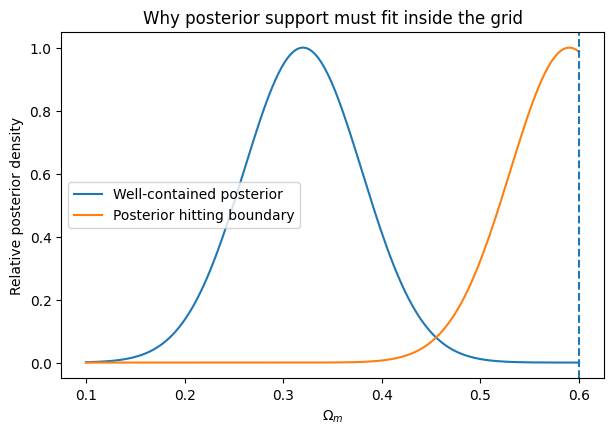

In [6]:
# Conceptual sketch:
# good grid coverage versus boundary truncation.

omega_demo = np.linspace(
    0.10,
    0.60,
    160,
)

like_inside = np.exp(
    -0.5
    * (
        (omega_demo - 0.32)
        / 0.06
    ) ** 2
)

like_edge = np.exp(
    -0.5
    * (
        (omega_demo - 0.59)
        / 0.06
    ) ** 2
)

fig, ax = plt.subplots(
    figsize=(7, 4.5),
)

ax.plot(
    omega_demo,
    like_inside,
    label="Well-contained posterior",
)

ax.plot(
    omega_demo,
    like_edge,
    label="Posterior hitting boundary",
)

ax.axvline(
    0.60,
    linestyle="--",
)

ax.set_xlabel(
    r"$\Omega_m$"
)

ax.set_ylabel(
    "Relative posterior density"
)

ax.set_title(
    "Why posterior support must fit inside the grid"
)

ax.legend()

plt.show()

# 6. Computing the posterior

Real astronomical posteriors are often not analytically normalizable.

Common numerical strategies include:

### Grid evaluation

Transparent and exact on the grid, but scales poorly with dimension.

### Laplace approximation

Approximates the posterior by a multivariate Gaussian near the mode. Fast, but  
weak for skewness, boundaries and multimodality.

### Variational inference

Finds an approximate posterior from a simpler distribution family. Fast, but  
can miss structure.

### MCMC

Generates samples distributed according to the posterior. Powerful but  
requires convergence diagnostics.

Lab 04 uses a **2-D grid** because it is the simplest reliable method for this  
problem.

## 6.1 Stable normalization on a grid

For a regular grid in $(\Omega_m,M_B)$ we evaluate the unnormalized log posterior at  
every grid point:

$$
a_{ij}
=
\log\mathcal L_{ij}
+
\log p(\Omega_{m,i})
+
\log p(M_{B,j}).
$$

The normalized posterior probability assigned to cell $(i,j)$ is

$$
P_{ij}
=
\frac{
\exp(a_{ij})
}{
\sum_{kl}
\exp(a_{kl})
}.
$$

In real problems the log-likelihood values can be very negative. Directly  
exponentiating them may cause numerical underflow, turning meaningful but  
small probabilities into zeros.

A stable solution is the log-sum-exp identity. Let $a_{\max}$ be the largest  
log-posterior value. Then

$$
\log Z
=
a_{\max}
+
\log
\sum_{ij}
\exp
\left(
a_{ij}-a_{\max}
\right).
$$

The normalized log posterior is

$$
\log P_{ij}
=
a_{ij}
-
\log Z.
$$

Subtracting $a_{\max}$ does not change relative probabilities, but it keeps the  
exponentials in a numerically safe range. This is why the Lab 04 code uses  
`logsumexp`.

## 6.2 Numerical checks for a grid posterior

Check:

- posterior normalization;
- grid resolution;
- whether probability mass reaches the boundaries;
- whether extending the grid changes the result;
- whether the joint shape is adequately resolved.

A computation that runs is not automatically a trustworthy inference.

## 6.3 Week 5 preview: convergence diagnostics

This is **extended reading**.

MCMC output must be checked.

Important diagnostics include:

### $\hat R$

Compares between-chain and within-chain variation.

### Effective sample size

Measures how many independent draws the autocorrelated chain is equivalent to.

### Divergences

Warn that the sampler may not have explored some posterior geometry reliably.

The broad lesson is:

$$
\boxed{
\text{a sampler that finishes is not necessarily a sampler that succeeded}.
}
$$

Full derivation and use are reserved for Week 5.

## 6.4 Computational failure can indicate model failure

Difficult sampling may reflect:

- multiple modes;
- non-identifiability;
- strong nonlinear correlations;
- poor scaling;
- extreme/vacuous priors;
- pathological boundaries.

Before blaming the algorithm, examine the model.

# 7. Joint Pantheon+ posterior

The Week 4 posterior is

$$
p(\Omega_m,M_B\mid D)
\propto
\mathcal L(D\mid\Omega_m,M_B)
p(\Omega_m)p(M_B).
$$

The joint posterior shows:

- favored parameter combinations;
- parameter correlation;
- degeneracy direction;
- truncation by prior boundaries;
- asymmetry or multimodality.

Joint geometry is scientifically informative.

## 7.1 Why a correlation coefficient is not enough

A joint posterior contains more information than separate one-dimensional  
intervals and more information than a single correlation coefficient.

A correlation coefficient can describe the average linear association between  
two parameters, but it cannot reveal whether the posterior is curved,  
multimodal, truncated by a boundary, skewed or strongly non-Gaussian.

For the $(\Omega_m,M_B)$ problem, posterior orientation has a physical interpretation.  
If an increase in $\Omega_m$ can be partly compensated by a change in $M_B$, then  
the posterior will be elongated along the corresponding degeneracy direction.

That geometry matters when we report uncertainties. Two narrow marginal  
intervals can conceal a strong joint degeneracy, while a broad marginal  
interval can result from a thin but strongly tilted joint posterior.

> **Practical rule**
>
> Inspect the joint posterior before compressing the result into separate  
> “best value ± uncertainty” statements.

# 8. Marginalization

If $\Omega_m$ is the main estimand and $M_B$ is a nuisance parameter,

$$
\boxed{
p(\Omega_m\mid D)
=
\int
p(\Omega_m,M_B\mid D)\,dM_B.
}
$$

On a regular grid,

$$
p(\Omega_{m,i}\mid D)
\propto
\sum_jP_{ij}.
$$

The common grid spacing cancels when the marginal is normalized.

## 8.1 Marginalization versus profiling

Marginalization and profiling both remove a nuisance parameter from a  
two-dimensional problem, but they do so in fundamentally different ways.

The profile likelihood keeps, for each value of $\Omega_m$, only the nuisance  
value $M_B$ that maximizes the likelihood:

$$
\mathcal L_{\rm prof}(\Omega_m)
=
\max_{M_B}
\mathcal L(\Omega_m,M_B).
$$

Bayesian marginalization instead integrates over all possible nuisance values,  
weighted by their posterior probability:

$$
p(\Omega_m\mid D)
=
\int
p(\Omega_m,M_B\mid D)
\,dM_B.
$$

Profiling asks, “what is the best nuisance value available at this $\Omega_m$?”  
Marginalization asks, “after accounting for the full uncertainty in the  
nuisance parameter, how much posterior probability remains at this $\Omega_m$?”

Because the operations are different, the profile-likelihood maximum from Lab  
03 and the posterior median or mode from Lab 04 need not be numerically  
identical.

## 8.2 Posterior mean, median and mode

### Mode

$$
\theta_{\rm mode}
=
\arg\max_\theta p(\theta\mid D).
$$

### Mean

$$
E[\theta\mid D]
=
\int\theta p(\theta\mid D)d\theta.
$$

### Median

$$
P(\theta<\theta_{\rm med}\mid D)=0.5.
$$

For a symmetric Gaussian posterior they are nearly identical.

For skewed or multimodal posteriors they can differ substantially.

## 8.3 Credible intervals

For a one-dimensional marginal posterior we define the posterior cumulative  
distribution function

$$
F(\theta)
=
\int_{-\infty}^{\theta}
p(\theta'\mid D)
\,d\theta'.
$$

A central equal-tail 68% credible interval is

$$
\left[
F^{-1}(0.16),
F^{-1}(0.84)
\right].
$$

The Bayesian interpretation is direct:

> Conditional on the adopted model, likelihood and prior, 68% of posterior  
> probability lies inside this interval.

This is not the frequentist interpretation of a 68% confidence interval. A  
frequentist confidence procedure refers to the long-run coverage of intervals  
constructed from repeated datasets; it does not assign a probability to the  
fixed unknown parameter after the data have been observed.

Keeping these interpretations distinct prevents one of the most common  
terminology errors in scientific papers.

## 8.4 Joint credible regions

For two parameters we want a region in the joint parameter plane containing a  
specified fraction of posterior probability.

A highest-density style region can be defined as

$$
R_\alpha
=
\left\{
\theta:
p(\theta\mid D)
\ge
t_\alpha
\right\},
$$

where the threshold $t_\alpha$ is chosen so that

$$
\int_{R_\alpha}
p(\theta\mid D)
\,d\theta
=
\alpha.
$$

For example, a 68% credible region is the collection of high-posterior-density  
points whose total enclosed posterior probability is 0.68.

This is why plotting an arbitrary contour level is not enough. A contour at  
“68% of the maximum density” does not generally enclose 68% of posterior  
probability. The threshold must be found from the integrated probability mass.

## Visualizing Bayes' theorem in one dimension

In one parameter dimension, Bayes' theorem can be visualized as

$$
\text{posterior}
\propto
\text{likelihood}
\times
\text{prior}.
$$

A broad prior may leave the likelihood almost unchanged.

An informative prior can shift or narrow the posterior.

The following sketch is pedagogical only; it is not a Pantheon+ fit.

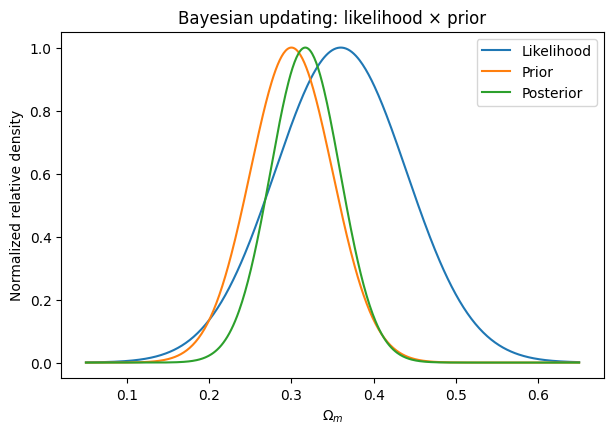

In [7]:
# Conceptual sketch:
# likelihood × prior -> posterior.

x = np.linspace(
    0.05,
    0.65,
    500,
)

likelihood_demo = np.exp(
    -0.5
    * (
        (x - 0.36)
        / 0.08
    ) ** 2
)

prior_demo = np.exp(
    -0.5
    * (
        (x - 0.30)
        / 0.05
    ) ** 2
)

posterior_demo = (
    likelihood_demo
    * prior_demo
)

likelihood_demo /= likelihood_demo.max()
prior_demo /= prior_demo.max()
posterior_demo /= posterior_demo.max()

fig, ax = plt.subplots(
    figsize=(7, 4.5),
)

ax.plot(
    x,
    likelihood_demo,
    label="Likelihood",
)

ax.plot(
    x,
    prior_demo,
    label="Prior",
)

ax.plot(
    x,
    posterior_demo,
    label="Posterior",
)

ax.set_xlabel(
    r"$\Omega_m$"
)

ax.set_ylabel(
    "Normalized relative density"
)

ax.set_title(
    "Bayesian updating: likelihood × prior"
)

ax.legend()

plt.show()

### Reading the sketch

The likelihood is centered where the data prefer the parameter.

The prior is centered where previous information places more probability.

The posterior compromises between them according to their relative widths.

If the likelihood is much narrower than the prior, the posterior is mostly  
data-dominated.

If the prior is much narrower than the likelihood, the posterior is strongly  
prior-sensitive.

# 9. Prior sensitivity

Lab 04 compares:

$$
\Omega_m\sim U(0.10,0.60)
$$

with

$$
\Omega_m\sim\mathcal N(0.30,0.03^2)
$$

truncated to the grid.

Compare:

- posterior location;
- posterior width;
- credible interval;
- joint geometry.

If the posterior changes materially, then prior information is contributing  
materially to the result.

## 9.1 How to report prior sensitivity

Prior sensitivity is not a nuisance to hide. It is information about how much  
the current dataset is contributing relative to previously encoded knowledge.

If a broad and a moderately informative prior produce nearly identical  
posteriors, the current likelihood is strongly informative over that parameter  
range.

If the posterior shifts substantially, or if its width changes strongly, then  
the scientific result remains prior-sensitive.

Useful reporting language is therefore explicit. For example:

> “The posterior location is largely data-dominated, while the width remains  
> moderately prior-sensitive.”

or

> “The inference changes materially under a defensible alternative prior, so  
> the parameter is not strongly constrained by the present dataset alone.”

The goal is not to prove that the prior has zero influence. In Bayesian  
inference the prior is part of the model. The goal is to understand whether  
reasonable prior choices change the scientific conclusion.

# 10. Posterior predictive distribution

After fitting,

$$
\boxed{
p(\tilde y\mid y)
=
\int
p(\tilde y\mid\theta)
p(\theta\mid y)
d\theta.
}
$$

This is a distribution over **replicated or future data**.

It averages the likelihood over posterior uncertainty in the parameters.

## 10.1 Predictive uncertainty versus parameter uncertainty

A posterior distribution quantifies uncertainty about parameters. A posterior  
predictive distribution quantifies uncertainty about observations that could  
be generated in a future or replicated experiment.

These are not the same object.

Even if the posterior for $\Omega_m$ became extremely narrow, a future Type Ia  
supernova magnitude would still have observational uncertainty and potentially  
intrinsic scatter. Parameter certainty therefore does not imply deterministic  
future data.

The posterior predictive distribution combines at least two sources of  
uncertainty: uncertainty in the parameters and stochastic variability in the  
measurement model.

There is also a third, more fundamental issue: the adopted model may be  
incomplete. Standard posterior prediction propagates uncertainty **within the  
model**; it does not automatically account for model misspecification. That is  
why predictive checking is necessary.

## 10.2 Important distinction in Lab 04

In Lab 04 students draw parameter pairs from the joint posterior,

$$
(\Omega_m^{(s)},M_B^{(s)})
\sim
p(\Omega_m,M_B\mid D),
$$

and use each draw to compute a Hubble relation

$$
m_B^{(s)}(z)
=
\mu
\left(
z;\Omega_m^{(s)},H_0
\right)
+
M_B^{(s)}.
$$

These curves show how uncertainty in the fitted parameters propagates into the  
mean theoretical Hubble relation.

They are **posterior-supported model curves**, not yet complete posterior  
predictive datasets.

To create a full replicated dataset we would also draw observational noise and  
covariance:

$$
\tilde{\mathbf m}^{(s)}
\sim
\mathcal N
\left(
\mathbf m_{\rm model}^{(s)},
C
\right).
$$

The distinction matters because a family of smooth model curves can look  
narrow even when the actual replicated observations would show substantial  
scatter.

# 11. Posterior predictive checks

A posterior predictive check asks:

> Does the fitted model generate observations with the same important  
> features as the real data?

Procedure:

1. draw $\theta^{(s)}\sim p(\theta\mid y)$;
2. draw replicated data
   $$
\tilde y^{(s)}\sim p(\tilde y\mid\theta^{(s)});
$$
3. compare observed and replicated data.

## 11.1 Test statistics for posterior predictive checks

A posterior predictive check compares the observed data with replicated data  
generated by the fitted model.

To make that comparison scientifically targeted, we choose a statistic $T(y)$  
that is sensitive to a plausible type of model failure.

For Pantheon+ we could examine

$$
T_1
=
\operatorname{median}(r),
$$

which detects a systematic residual offset,

$$
T_2
=
\operatorname{SD}(r),
$$

which tests the overall width of the residual distribution, or

$$
T_3
=
\operatorname{MAD}(r),
$$

which measures residual scale more robustly in the presence of outliers.

We could also define a statistic for a residual trend with redshift, or the  
fraction of objects with unusually large residuals.

The purpose is not to search blindly for any discrepancy. A good posterior  
predictive statistic corresponds to a scientifically meaningful failure mode  
that we would care about if it appeared in the real observations.

## 11.2 Posterior predictive $p$-value

One numerical summary of a posterior predictive check is

$$
p_B
=
P
\left[
T(\tilde y)
\ge
T(y_{\rm obs})
\mid
y_{\rm obs}
\right].
$$

Operationally, we generate many posterior predictive replicated datasets,  
calculate the statistic $T$ for each one, and measure what fraction are at  
least as extreme as the observed statistic.

If the observed statistic lies near the center of the replicated distribution,  
the fitted model is capable of reproducing that feature of the data.

If the observed statistic lies far into a tail, the model has difficulty  
reproducing that feature and should be investigated.

A posterior predictive $p$-value is **not** a classical frequentist  
p-value. The observed data have already been used to construct the posterior  
predictive distribution, so the usual uniform-under-the-null interpretation  
does not apply. We should therefore not use a mechanical “0.05 significance  
threshold” for posterior predictive checks.

## 11.3 Visual posterior predictive checks

Posterior predictive checks are often most informative when they are visual.

A distribution overlay can compare the observed residual distribution with  
many replicated residual distributions. A residual-versus-redshift plot can  
reveal systematic trends that a global summary statistic would miss. A Q–Q  
plot can show whether the model reproduces the central distribution but fails  
in the tails.

Conditional checks are particularly important in survey astronomy. A model may  
reproduce the full dataset reasonably well while failing for one redshift  
range, one contributing survey, or one host-galaxy population.

Therefore “the global posterior predictive distribution looks acceptable” is  
not the end of model criticism. We should ask whether the model reproduces the  
features of the data that matter for the scientific question.

## 11.4 What a failed posterior predictive check can teach us

A failed predictive check is useful because different discrepancies suggest  
different model deficiencies.

If the predicted residual distribution is too narrow, the model may be missing  
intrinsic scatter, correlated uncertainty or another source of variance.

If the observed residuals have much heavier tails than the replicated data, a  
Gaussian likelihood may be inadequate. A Student-$t$ likelihood or an  
explicit outlier-mixture model might be more appropriate.

If residuals show a systematic redshift trend, the problem could lie in the  
physical model, calibration, survey selection, or another redshift-dependent  
effect.

If the model fits most observations but fails for one subpopulation, a  
hierarchical or mixture model may be needed.

The important principle is that Bayesian analysis is iterative:

$$
\boxed{
\text{specify}
\rightarrow
\text{fit}
\rightarrow
\text{check}
\rightarrow
\text{revise}
}.
$$

Posterior predictive checking is therefore not an optional decorative plot at  
the end of inference. It is part of the scientific process of deciding whether  
the adopted model is an adequate description of the data.

# 12. Extended example: multiple measurements of one latent quantity

**Extended reading / Week 5 bridge**

Suppose $n$ stars in one cluster share a common distance $d_{\rm cl}$, with

$$
y_i
\sim
\mathcal N
\left(
\frac1{d_{\rm cl}},
\sigma_i^2
\right).
$$

Assuming conditional independence,

$$
p(\mathbf y\mid d_{\rm cl})
=
\prod_i
\mathcal N
\left(
y_i\mid1/d_{\rm cl},\sigma_i^2
\right).
$$

Define the total precision

$$
\tau^{-2}
=
\sum_i\sigma_i^{-2}
$$

and weighted effective parallax

$$
\varpi_{\rm eff}
=
\tau^2
\sum_i
\frac{y_i}{\sigma_i^2}.
$$

Then the likelihood reduces to the form of one effective Gaussian measurement.

As independent information accumulates, the likelihood generally becomes more  
informative relative to the prior.

## 12.1 The prior depends on the scientific population

A prior appropriate for a random field star is not automatically appropriate  
for a known cluster member.

The symbol $d$ is the same, but the scientific context is different.

Therefore:

$$
\boxed{
\text{priors describe the scientific population, not merely the parameter name}.
}
$$

# 13. Practical Bayesian-analysis checklist

## Before fitting

- [ ] State the estimand.
- [ ] Identify the observed data product.
- [ ] Write the generative/forward model.
- [ ] Choose a likelihood consistent with the data type.
- [ ] Include heteroscedastic errors/covariance where required.
- [ ] Include intrinsic scatter if needed.
- [ ] Specify every prior and its support.
- [ ] Avoid absurdly broad priors.
- [ ] Avoid priors so restrictive that the data cannot move them.
- [ ] Run a prior predictive sanity check when feasible.

## During computation

### Grid

- [ ] Posterior is normalized.
- [ ] Grid resolution is adequate.
- [ ] Posterior mass does not depend on artificial grid boundaries.

### MCMC — Week 5

- [ ] Multiple chains agree.
- [ ] $\hat R$ is satisfactory.
- [ ] Bulk/tail effective sample sizes are adequate.
- [ ] Trace plots are stationary and mixing.
- [ ] Divergences are absent or investigated.

## After fitting

- [ ] Inspect joint posterior geometry.
- [ ] Marginalize nuisance parameters correctly.
- [ ] Use posterior summaries appropriate to posterior shape.
- [ ] Test prior sensitivity.
- [ ] Generate posterior-supported or posterior-predictive observations.
- [ ] Check residual structure.
- [ ] Perform posterior predictive checks where feasible.
- [ ] Revise the model if systematic failures remain.

## Communicating the result

Report:

1. observed data and their uncertainty structure;
2. generative model;
3. likelihood;
4. parameters and nuisance parameters;
5. priors and motivation;
6. covariance treatment;
7. posterior geometry and summaries;
8. prior sensitivity;
9. predictive/model checks;
10. limitations.

A posterior without its likelihood and priors is not a reproducible scientific  
result.

# 14. Five-line statement for Lab 04

### Estimand

$$
p(\Omega_m,M_B\mid D)
$$

and especially

$$
p(\Omega_m\mid D).
$$

### Observed data

Pantheon+ standardized apparent magnitudes, redshifts and released statistical  
covariance.

### Generative assumptions

$$
m_B^{\rm corr}
=
\mu(z;\Omega_m,H_0)+M_B+\epsilon,
$$

with fixed $H_0$ zero-point convention and

$$
\boldsymbol\epsilon\sim\mathcal N(\mathbf0,C).
$$

### Uncertainty / selection

Statistical covariance is included. Systematic covariance is deferred to Week
5. Prior support and the teaching sample mask condition the result.

### Validation / falsification

Distrust or revise the analysis if:

- posterior mass hits the grid/prior boundary;
- defensible priors materially change the conclusion;
- residuals show systematic trends;
- posterior-predictive behavior fails to resemble the data.

# 15. Bridge to Lab 04

Students will:

1. load real Pantheon+ data and statistical covariance;
2. compute $\chi^2(\Omega_m,M_B)$;
3. construct the likelihood;
4. apply priors;
5. normalize the joint posterior;
6. inspect 2-D posterior geometry;
7. calculate 68% and 95% enclosed-probability contours;
8. marginalize over $M_B$;
9. calculate credible intervals;
10. compare with Lab 03 profile likelihood;
11. test an informative prior;
12. inspect posterior-supported Hubble relations;
13. distinguish data information from prior/model assumptions.

# 16. Bridge to Week 5

Week 4 uses a two-dimensional grid so the posterior can be inspected directly.

Week 5 asks whether MCMC can recover the same target and how we diagnose the  
sampler.

We then add the full statistical+systematic covariance.

The principle is:

$$
\boxed{
\text{use the simplest reliable computation method that answers the scientific question}.
}
$$

# 17. Final synthesis

Bayesian inference is a workflow, not a single algorithm.

$$
\boxed{
\text{scientific question}
\rightarrow
\text{generative model}
\rightarrow
\text{likelihood}
\rightarrow
\text{prior}
\rightarrow
\text{posterior}
\rightarrow
\text{prediction}
\rightarrow
\text{model criticism}.
}
$$

For Pantheon+:

$$
(\Omega_m,M_B)
\rightarrow
m_B^{\rm corr}(z)
\rightarrow
D
$$

is the forward direction.

$$
D
\rightarrow
p(\Omega_m,M_B\mid D)
\rightarrow
p(\Omega_m\mid D)
$$

is the inferential direction.

The posterior is conditional on

$$
\boxed{
\text{data}
+
\text{likelihood}
+
\text{prior}
+
\text{model}.
}
$$

The posterior predictive distribution takes us back to observation space,  
where the fitted model can be tested against the real Universe.

# 18. Recommended reading

### Primary source adapted here
Andy Casey, **Practical Bayesian Inference in Astronomy**  
<https://astrowizici.st/teaching/data-analysis/workflow_model_building/lecture-04/>

### Primary reference behind the Casey lecture
Eadie, G. M., Speagle, J. S., Cisewski-Kehe, J., et al. (2023), **Practical  
Guidance for Bayesian Inference in Astronomy**, arXiv:2302.04703.

### Broader workflow
- Gelman et al. — Bayesian workflow
- Betancourt — principled Bayesian workflow
- Vehtari et al. — modern $\hat R$ and effective sample size

### Course learning material
- Crete 06 — Bayesian 1
- Crete 06 — Bayes Ball
- Crete 06 — Bayesian 3

Read Casey for the **full modelling workflow**, this notebook for the  
**cosmology translation**, and Lab 04 for the **real Pantheon+  
implementation**.